# Climate and ground-temperature sensitivity

Keep geometry and use fixed to isolate two environmental assumptions.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

This is a matched sensitivity experiment. A `BuildingSpec.updated(climate=...)` replacement changes weather while keeping the other inputs fixed. A separate `EnvelopeSpec` replacement changes the monthly ground-boundary temperatures, so the two effects can be interpreted separately.

Ground temperatures are explicit prescribed boundary conditions, not values inferred from the EPW and not a soil solver. The documentation's climate/context figure is a useful reading example: compare matched baselines within a climate and report absolute energy as well as relative change. The figure's experiment differs from this notebook's ground-temperature cases.

Reference: [Retained example: context sensitivity across three climates](../../docs/figures/context-sensitivity.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Create matched climate cases

Only the weather changes between these annual runs. Small cases keep the experiment reviewable; they do not calibrate an entire climate region.

### Read the code and output

Each call to `runner.run` receives the same geometry, envelope and operations with a new climate. The resulting heating EUI removes floor-area scale, which is already fixed here. It does not remove climate effects or make the values weather-normalized measured performance.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

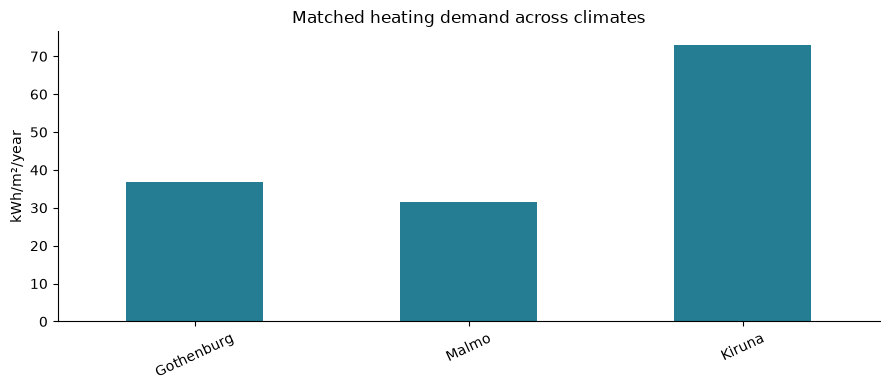

In [2]:
base = building()
runner = EnergyPlusRunner(engine())
results = {}
for city in ["Gothenburg","Malmo","Kiruna"]:
    spec = base.updated(climate=climate_from_epw(epw(city)))
    results[city] = runner.run(spec, OUT / city)
bars({city:r.scalars["space_heating_demand_eui_kwh_m2"] for city,r in results.items()}, "kWh/m²/year", "Matched heating demand across climates")

## Disclose ground assumptions

The default monthly ground temperatures are an uncalibrated engine assumption. Supply an explicit source for an alternative; constant deep-ground temperatures are not outdoor air temperatures.

### Read the code and output

Read the actual twelve supplied temperatures and their source label before interpreting the result. A constant alternative tests sensitivity to a boundary assumption; it does not claim a calibrated ground temperature. The plotted lines make this input difference inspectable independently of the energy output.

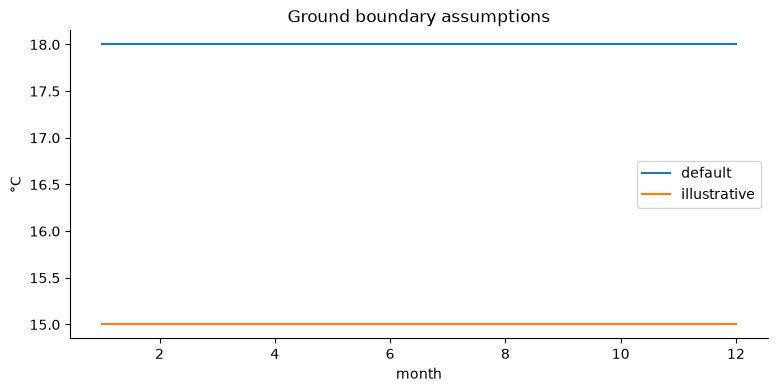

In [3]:
ground = GroundTemperatureSpec(monthly_temperatures_c=(15.,)*12, source="illustrative constant 15C sensitivity")
changed = base.updated(envelope=base.envelope.updated(ground_temperature=ground))
ground_runner = EnergyPlusRunner(engine(), settings=CompilerSettings(hourly_outputs=(HourlyOutputRequest(name="Surface Inside Face Conduction Heat Transfer Energy"),)))
cold_ground = ground_runner.run(changed, OUT / "ground15")
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({"default":base.envelope.ground_temperature.monthly_temperatures_c,"illustrative":ground.monthly_temperatures_c},index=range(1,13)).plot(ax=ax, ylabel="°C",xlabel="month",title="Ground boundary assumptions")
plt.show(); plt.close(fig)

## Compare energy and retained evidence

Ground conduction has both directions over the year. The annual absolute-transfer metric should not be interpreted as net heat loss.

### Read the code and output

Compare only the Gothenburg baseline with the changed-ground Gothenburg run to isolate the ground effect. `annual_absolute_ground_transfer_kwh` sums magnitudes over time; alternating gains and losses do not cancel in that metric. It therefore cannot be labelled net ground heat loss.

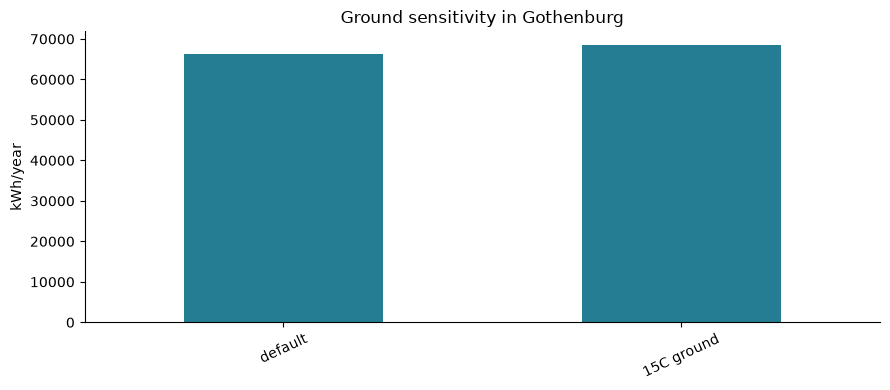

,field,value
0,default_source,energyplus_24_2_default_18C_uncalibrated
1,alternative_source,illustrative constant 15C sensitivity
2,absolute_ground_transfer_kwh,10864.396706755178


In [4]:
bars({"default":results["Gothenburg"].scalars["space_heating_demand_kwh"], "15C ground":cold_ground.scalars["space_heating_demand_kwh"]}, "kWh/year", "Ground sensitivity in Gothenburg")
table({"default_source":base.envelope.ground_temperature.source,"alternative_source":ground.source,"absolute_ground_transfer_kwh":cold_ground.scalars["annual_absolute_ground_transfer_kwh"]})
assert changed.geometry == base.geometry

## Interpretation and next experiment

Sensitivity to an assumption is not evidence that either boundary condition is correct. Ground-data sourcing remains the responsibility of the caller.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.